In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/wine-quality-dataset")

print("Path to dataset files:", path)

Path to dataset files: /Users/evabankeeva/.cache/kagglehub/datasets/yasserh/wine-quality-dataset/versions/1


In [2]:
import os
from itertools import combinations

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
df0 = pd.read_csv(os.path.join(path, 'WineQT.csv'), index_col='Id')
df0

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
Id,,,,,,,,,,,,
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1592,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1593,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5


In [ ]:
summary_df = pd.DataFrame({
    'dtype':         df0.dtypes.astype(str),
    'Уникальных':    df0.nunique(),
    'Пропусков':     df0.isna().sum(),
    'Мода уровня 1':          df0.mode().iloc[0],
    'Среднее':       df0.mean(),
    'Медиана':       df0.median(),
    'Стд.откл.':     df0.std(),
    'Дисперсия':     df0.var(),
    'Мин':           df0.min(),
    'Макс':          df0.max(),
    'Размах':        df0.max() - df0.min(),
    'IQR':           (df0.quantile(0.75, )
                      - df0.quantile(0.25, )),
    'Асимметрия':    df0.skew(),
    'Эксцесс':       df0.kurt(),
})

summary_df

,dtype,Уникальных,Пропусков,Мода уровня 1,Среднее,Медиана,Стд.откл.,Дисперсия,Мин,Макс,Размах,IQR,Асимметрия,Эксцесс
fixed acidity,float64,91,0,7.2000,8.311111,7.90000,1.747595,3.054088,4.60000,15.90000,11.30000,2.000000,1.044930,1.384614
volatile acidity,float64,135,0,0.5000,0.531339,0.52000,0.179633,0.032268,0.12000,1.58000,1.46000,0.247500,0.681547,1.375531
citric acid,float64,77,0,0.0000,0.268364,0.25000,0.196686,0.038685,0.00000,1.00000,1.00000,0.330000,0.371561,-0.714686
residual sugar,float64,80,0,2.0000,2.532152,2.20000,1.355917,1.838512,0.90000,15.50000,14.60000,0.700000,4.361096,27.675366
chlorides,float64,131,0,0.0800,0.086933,0.07900,0.047267,0.002234,0.01200,0.61100,0.59900,0.020000,6.026360,47.078324
free sulfur dioxide,float64,53,0,6.0000,15.615486,13.00000,10.250486,105.072466,1.00000,68.00000,67.00000,14.000000,1.231261,1.932170
total sulfur dioxide,float64,138,0,28.0000,45.914698,37.00000,32.782130,1074.668067,6.00000,289.00000,283.00000,40.000000,1.665766,5.098748
density,float64,388,0,0.9976,0.996730,0.99668,0.001925,0.000004,0.99007,1.00369,0.01362,0.002275,0.102395,0.888123
pH,float64,87,0,3.3000,3.311015,3.31000,0.156664,0.024544,2.74000,4.01000,1.27000,0.195000,0.221138,0.925791
sulphates,float64,89,0,0.6000,0.657708,0.62000,0.170399,0.029036,0.33000,2.00000,1.67000,0.180000,2.497266,12.017377


[2.3] Для всего датасета выполнить в форме Upset plot:
- визуализацию чисел объектов с пропущенными значениями для каждого варианта
группировки пропусков по признакам;
- визуализацию чисел объектов с повторяющимися значениями, равными друг другу
внутри одного признака, для каждого варианта группировки повторов по признакам.

In [5]:
def draw_upset(conditions, title):
    set_names = list(conditions.keys())
    n_sets = len(set_names)
    colors = plt.cm.tab20(np.linspace(0, 1, n_sets))
    intersections = {}

    for r in range(1, n_sets + 1):
        for combo in combinations(range(n_sets), r):

            mask = np.ones(len(conditions[set_names[0]]), dtype=bool)

            for i in range(n_sets):
                if i in combo:
                    mask = mask & conditions[set_names[i]]
                else:
                    mask = mask & ~conditions[set_names[i]]

            size = int(mask.sum())

            if size > 0:
                intersections[combo] = size

    if not intersections:
        print(f"[{title}] нет непустых пересечений — пропуск")
        return

    sorted_intersections = sorted(
    intersections.items(),
    key=lambda x: x[1],
    reverse=True)

    plot_sizes = [item[1] for item in sorted_intersections]
    plot_matrix = np.array(
        [[1 if i in combo else 0 for i in range(n_sets)]
         for combo, _ in sorted_intersections]
    ).T

    width = max(14, len(plot_sizes) * 0.45)
    height = max(7, n_sets * 0.45)

    fig = plt.figure(figsize=(width, height))
    gs = fig.add_gridspec(2, 2, width_ratios=[2, 5],
                          height_ratios=[3, 2], hspace=0.05, wspace=0.05)

    ax_sets   = fig.add_subplot(gs[1, 0])
    ax_bar    = fig.add_subplot(gs[0, 1])
    ax_matrix = fig.add_subplot(gs[1, 1])

    set_totals = [int(conditions[name].sum()) for name in set_names]
    y_pos_sets = np.arange(n_sets)
    max_total = max(set_totals) if max(set_totals) > 0 else 1

    ax_sets.barh(y_pos_sets, [-t for t in set_totals],
                 color=colors, edgecolor='white', linewidth=1)
    ax_sets.set_yticks(y_pos_sets)
    ax_sets.set_yticklabels([])
    ax_sets.set_ylim(-0.5, n_sets - 0.5)
    ax_sets.invert_yaxis()
    ax_sets.set_xlim(-max_total * 1.4, 0)
    ax_sets.set_xlabel('Set size', fontweight='bold', fontsize=11)
    ax_sets.spines['top'].set_visible(False)
    ax_sets.spines['right'].set_visible(False)
    ax_sets.spines['bottom'].set_visible(False)
    ax_sets.tick_params(axis='y', length=0)
    ax_sets.tick_params(axis='x', labelbottom=False)

    for i, total in enumerate(set_totals):
        ax_sets.text(-total - max_total * 0.02, i, str(total),
                     va='center', ha='right', fontweight='bold', fontsize=9)
    for i, name in enumerate(set_names):
        ax_sets.text(-max_total * 1.42, i, name,
                     va='center', ha='right', fontweight='bold',
                     fontsize=10, color=colors[i])

    y_pos_bar = np.arange(len(plot_sizes))
    bars = ax_bar.bar(y_pos_bar, plot_sizes,
                      color='#4472C4', edgecolor='white', linewidth=0.5)
    ax_bar.set_ylabel('Objects', fontweight='bold', fontsize=11)
    ax_bar.set_ylim(0, max(plot_sizes) * 1.15)
    ax_bar.set_xlim(-0.5, len(plot_sizes) - 0.5)
    ax_bar.spines['top'].set_visible(False)
    ax_bar.spines['right'].set_visible(False)
    ax_bar.spines['bottom'].set_visible(False)
    ax_bar.tick_params(axis='x', bottom=False, labelbottom=False)

    for bar, size in zip(bars, plot_sizes):
        height = bar.get_height()
        ax_bar.text(bar.get_x() + bar.get_width() / 2., height,
                    f'{size}', ha='center', va='bottom',
                    fontsize=8, fontweight='bold')

    for i in range(n_sets):
        bg_color = '#F5F5F5' if i % 2 == 0 else '#E8E8E8'
        ax_matrix.axhspan(i - 0.5, i + 0.5, color=bg_color, zorder=0)

    for col_idx in range(len(plot_sizes)):
        y_coords = np.where(plot_matrix[:, col_idx] == 1)[0]
        if len(y_coords) > 0:
            ax_matrix.plot([col_idx, col_idx],
                           [y_coords[0], y_coords[-1]],
                           color='#404040', linewidth=1.7,
                           zorder=2, solid_capstyle='round')
        for row_idx in range(n_sets):
            if row_idx in y_coords:
                ax_matrix.scatter(col_idx, row_idx,
                                  color=colors[row_idx], s=60, zorder=3)
            else:
                ax_matrix.scatter(col_idx, row_idx,
                                  color='#D0D0D0', s=60,
                                  zorder=1, alpha=0.6)

    ax_matrix.set_yticks(y_pos_sets)
    ax_matrix.set_yticklabels([])
    ax_matrix.set_ylim(-0.5, n_sets - 0.5)
    ax_matrix.invert_yaxis()
    ax_matrix.set_xlim(-0.5, len(plot_sizes) - 0.5)
    ax_matrix.tick_params(axis='x', bottom=False, labelbottom=False)
    ax_matrix.spines['top'].set_visible(False)
    ax_matrix.spines['right'].set_visible(False)
    ax_matrix.spines['bottom'].set_visible(False)
    ax_matrix.set_xlabel('Intersections', fontsize=9, style='italic')

    plt.suptitle(title, fontsize=13, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

Пропусков нет — график не строится


/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_13419/386018759.py:124: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


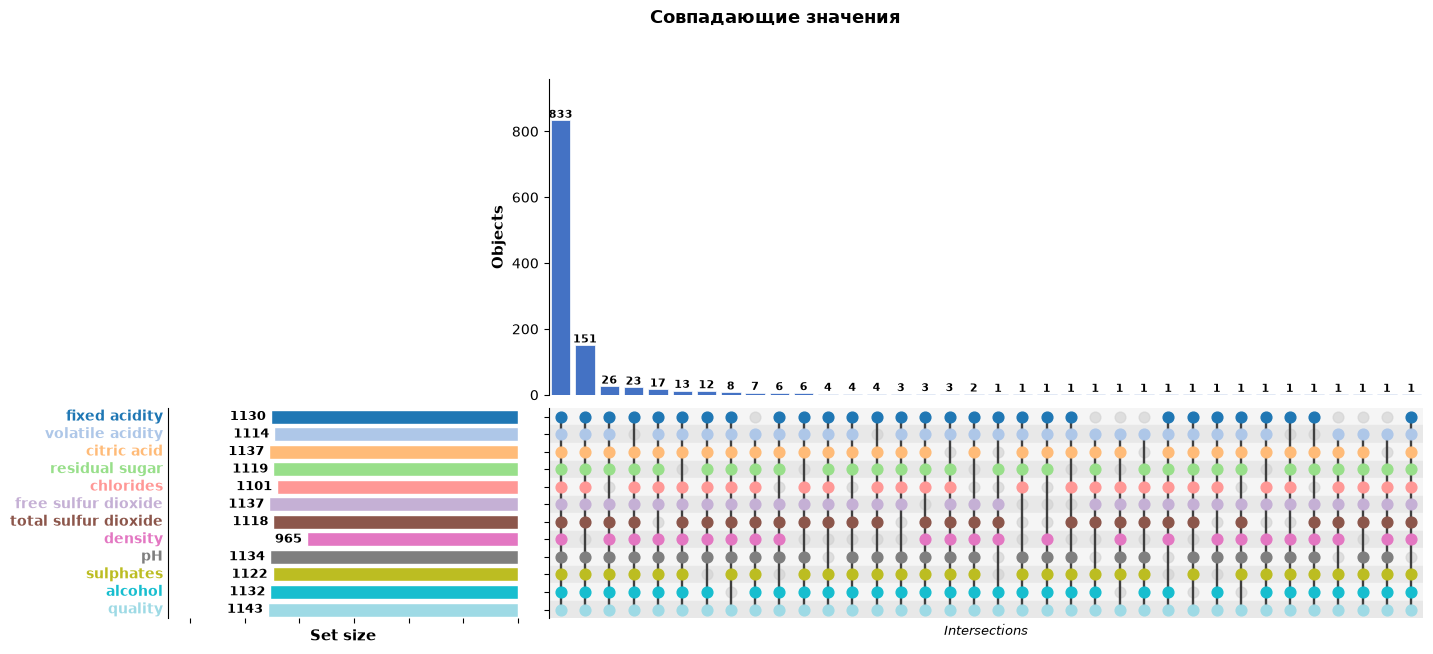

In [6]:
FEATURES = df0.columns.tolist()

# ---------- ПРОПУСКИ ----------
miss_conditions = {f'{col}_NaN': df0[col].isna() for col in FEATURES}
miss_conditions = {k: v for k, v in miss_conditions.items() if v.sum() > 0}

if miss_conditions:
    draw_upset(miss_conditions,
               f'Пропущенные значения по признакам')
else:
    print(f"Пропусков нет — график не строится")

# ---------- СОВПАДАЮЩИЕ ЗНАЧЕНИЯ ----------
eq_conditions = {}
for col in FEATURES:
    dup_mask = df0[col].duplicated(keep=False)
    if dup_mask.sum() > 0:
        eq_conditions[f'{col}'] = dup_mask

if eq_conditions:
    draw_upset(eq_conditions,
               f'Совпадающие значения')
else:
    print(f"Все значения уникальны — график не строится")

[2.4] Выбрать три класса и четыре количественных (недискретных) признака.
Сформировать на их основе «отфильтрованный» датасет df0m для дальнейшего
анализа, удалив из датасета все объекты, для которых не определены значения хотя бы
одного из выбранных четырех количественных признаков.

In [7]:
df0['quality'].value_counts()

quality
5    483
6    462
7    143
4     33
8     16
3      6
Name: count, dtype: int64

In [8]:
classes = [5, 6, 7]

quant_features = [
    'fixed acidity',
    'citric acid',
    'sulphates',
    'alcohol',
    'quality'
]

df0m = df0[
    df0['quality'].isin(classes)
][quant_features].copy()

df0m

,fixed acidity,citric acid,sulphates,alcohol,quality
Id,,,,,
0,7.4,0.00,0.56,9.4,5
1,7.8,0.00,0.68,9.8,5
2,7.8,0.04,0.65,9.8,5
3,11.2,0.56,0.58,9.8,6
4,7.4,0.00,0.56,9.4,5
...,...,...,...,...,...
1592,6.3,0.13,0.75,11.0,6
1593,6.8,0.08,0.82,9.5,6
1594,6.2,0.08,0.58,10.5,5


[2.5] Для датасетов df0 и df0m сравнительно вывести корреляции Пирсона, как в [1.5]

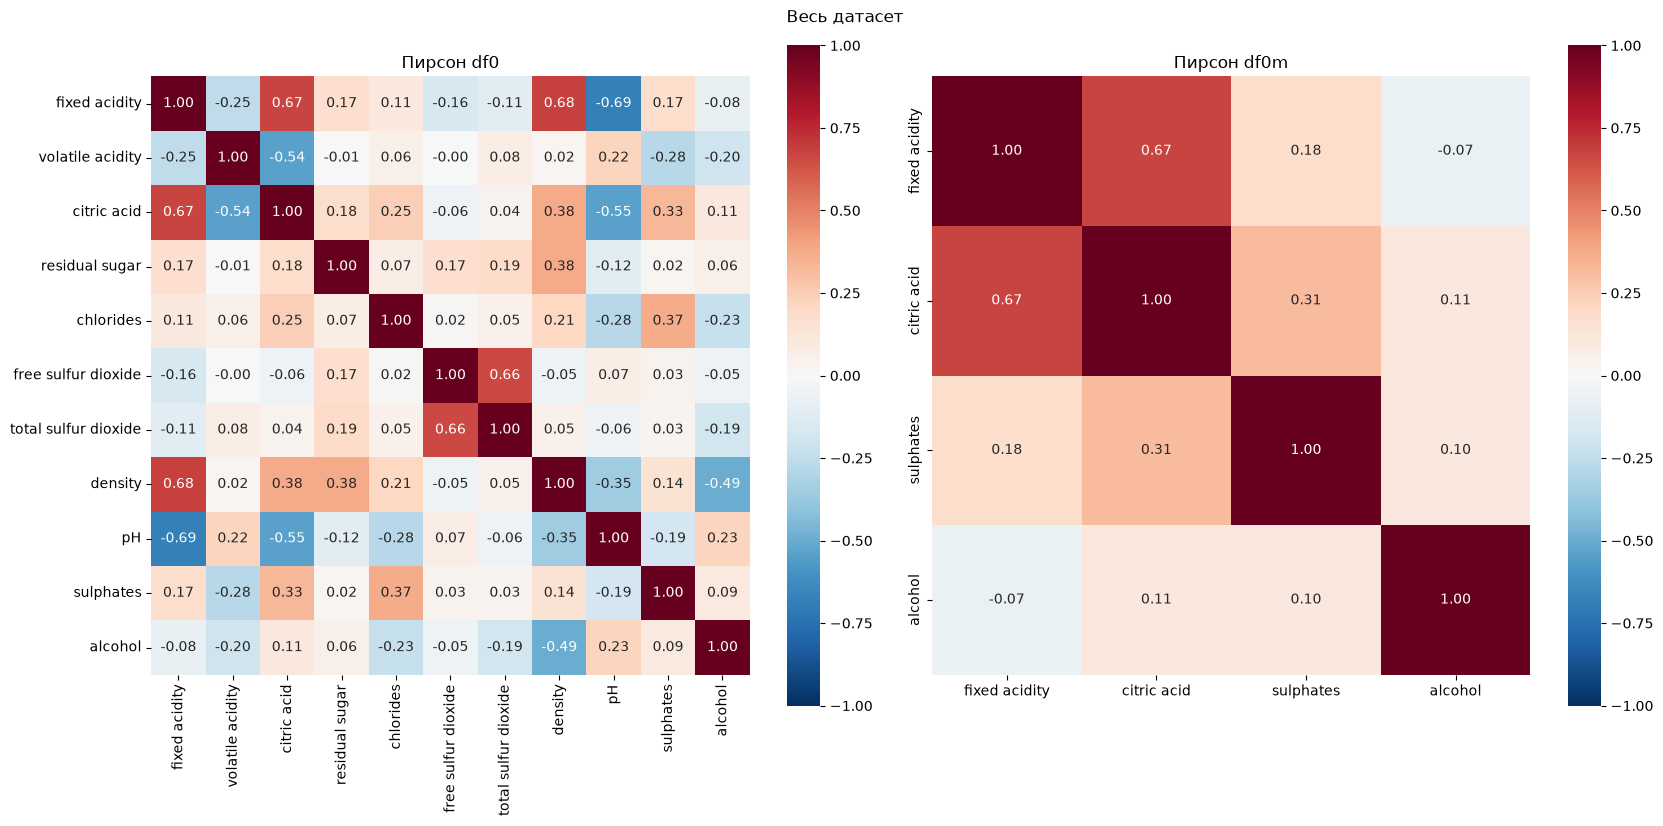

In [9]:
KW = dict(annot=True, fmt='.2f', cmap='RdBu_r',
          vmin=-1, vmax=1, center=0, square=True)

FEATURES.remove('quality')
quant_features.remove('quality')

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
fig.suptitle('Весь датасет')
sns.heatmap(df0[FEATURES].corr(method='pearson'), ax=axes[0], **KW).set_title('Пирсон df0')
sns.heatmap(df0m[quant_features].corr(method='pearson'), ax=axes[1], **KW).set_title('Пирсон df0m')
plt.tight_layout()
plt.show()

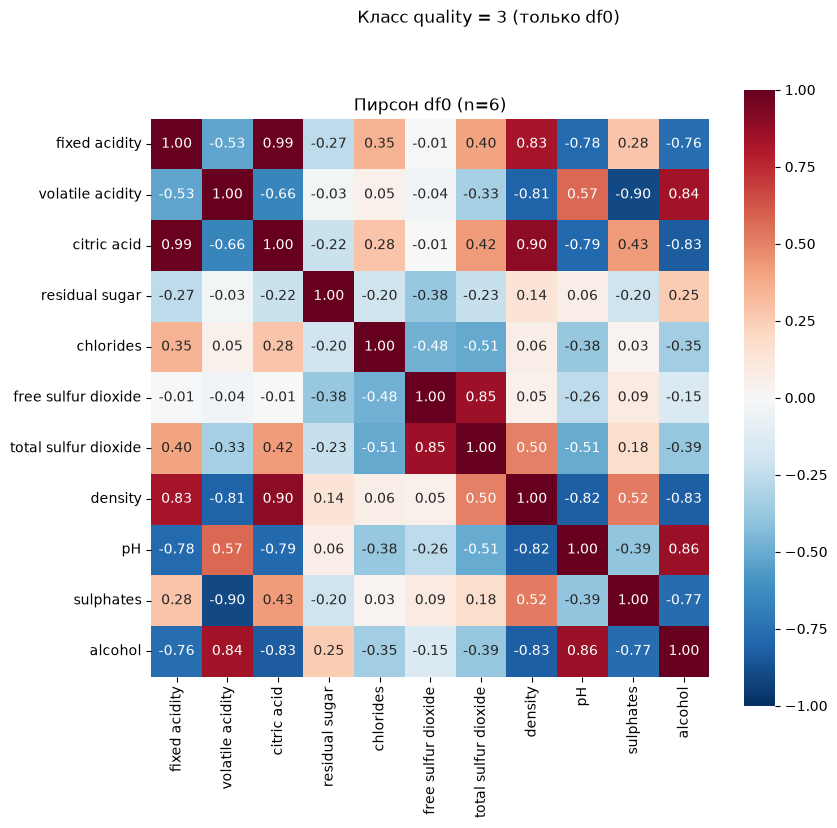

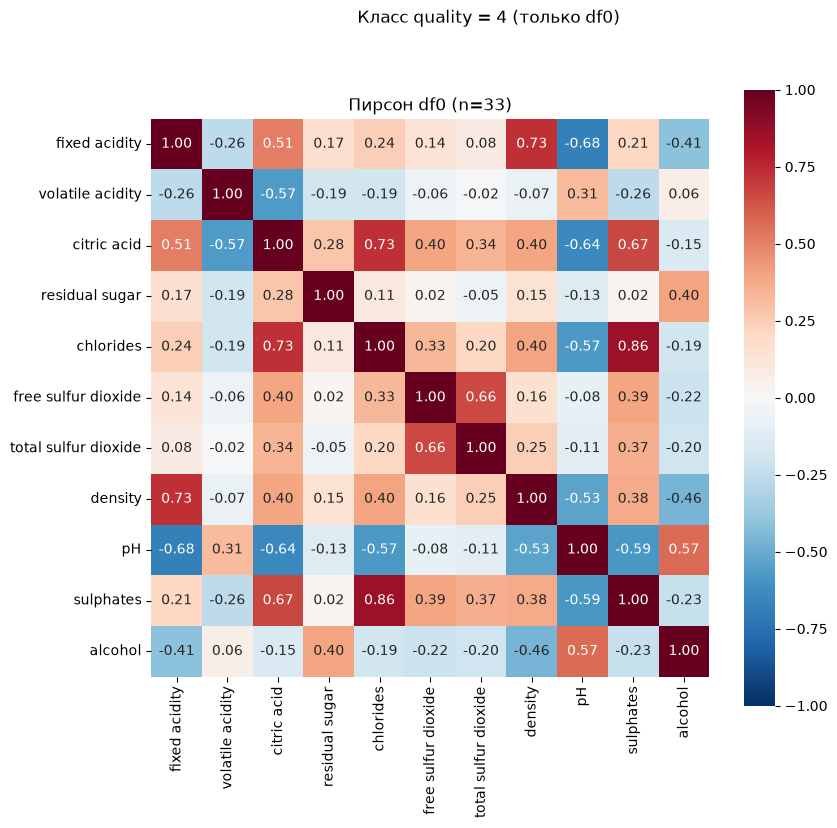

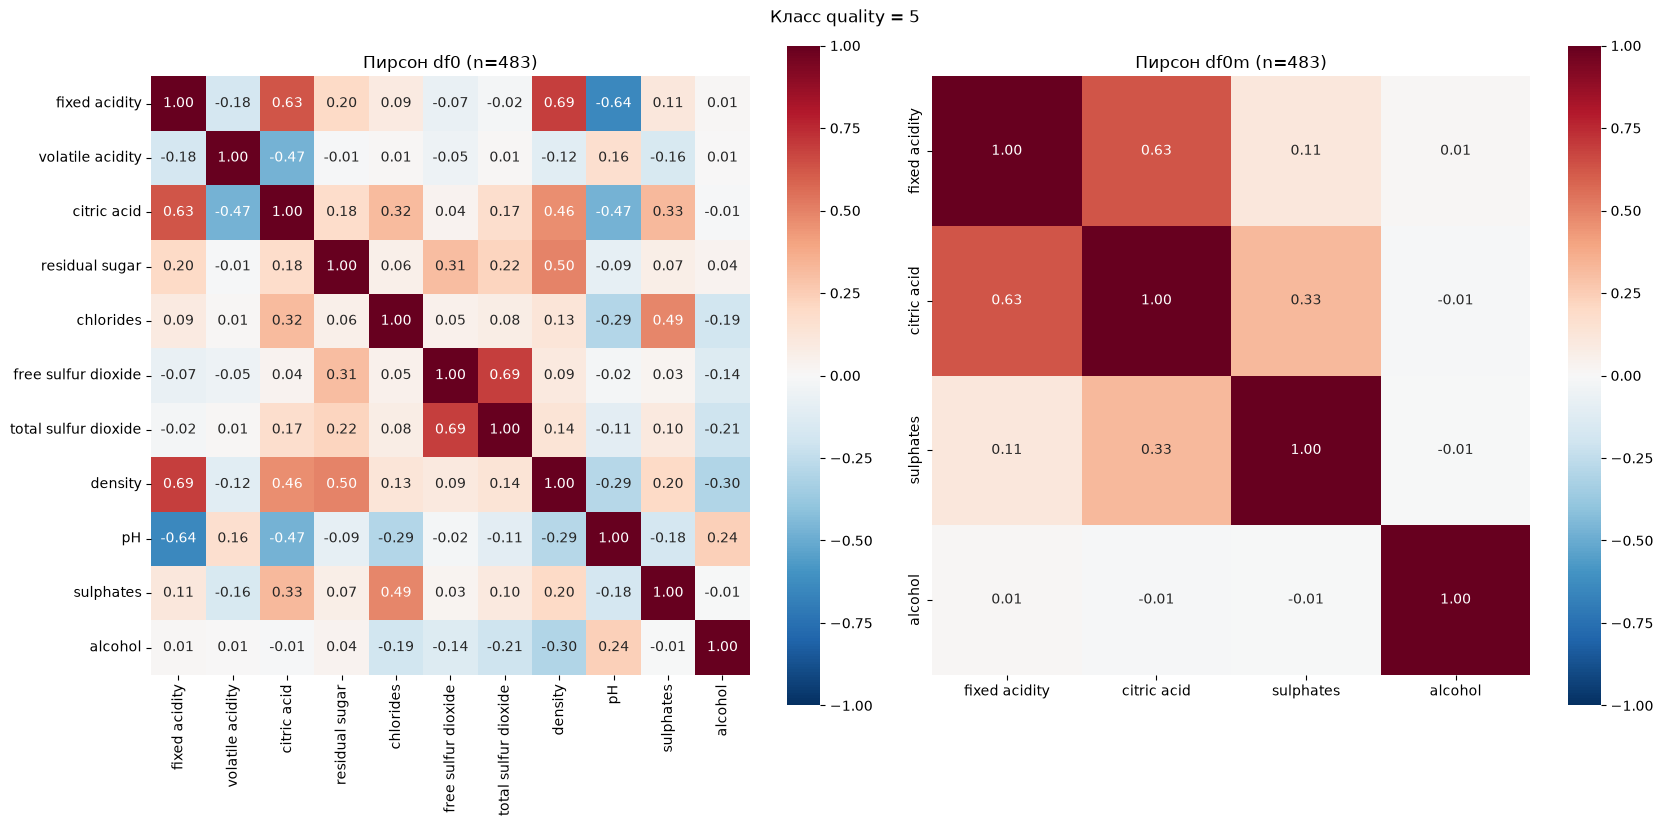

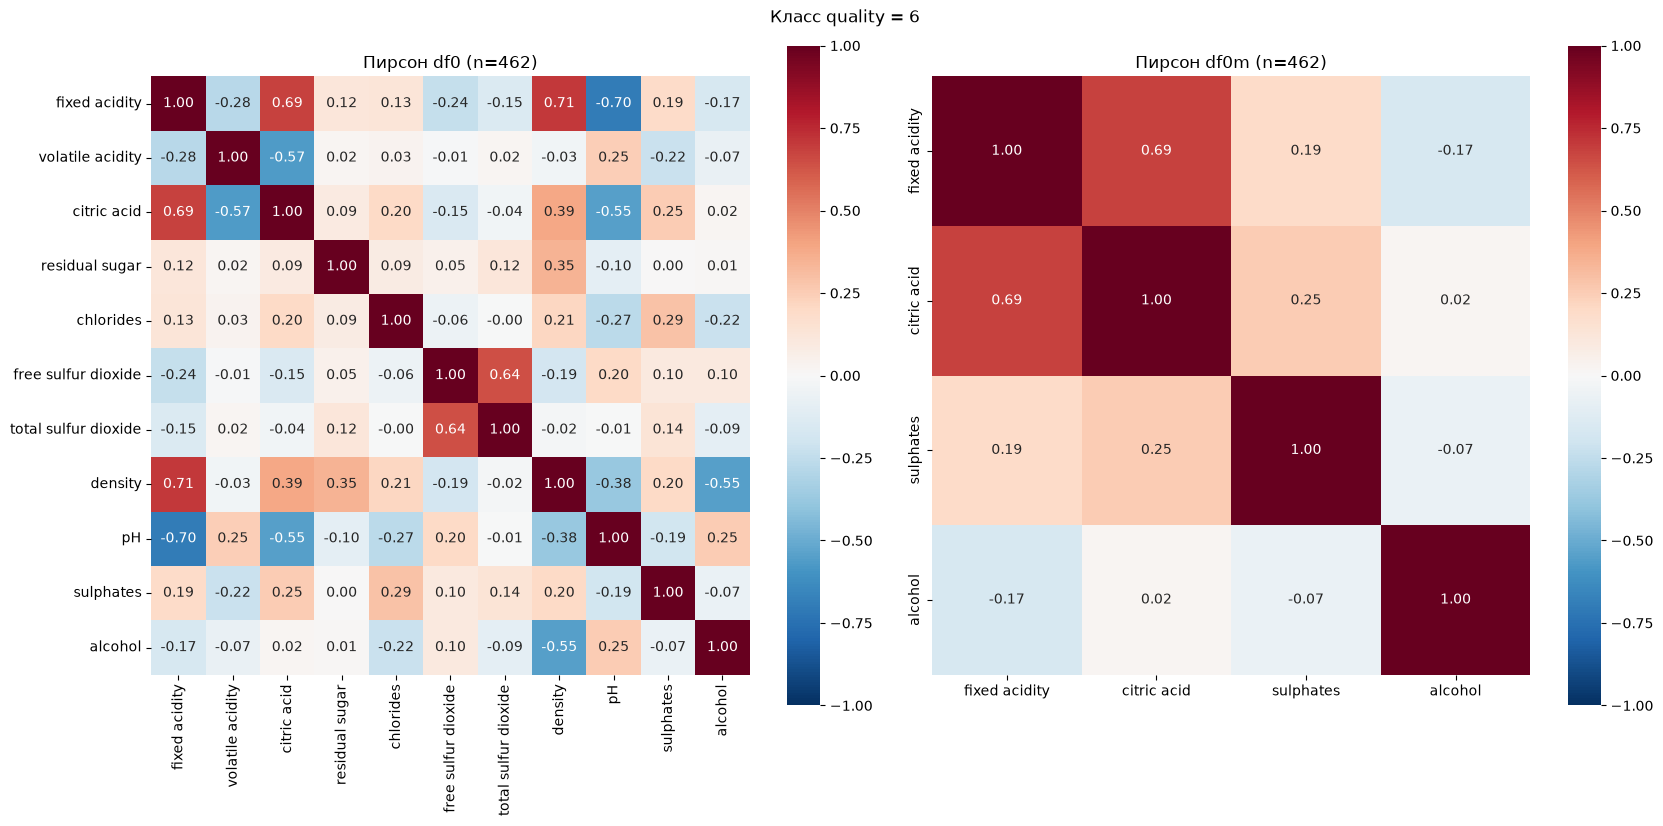

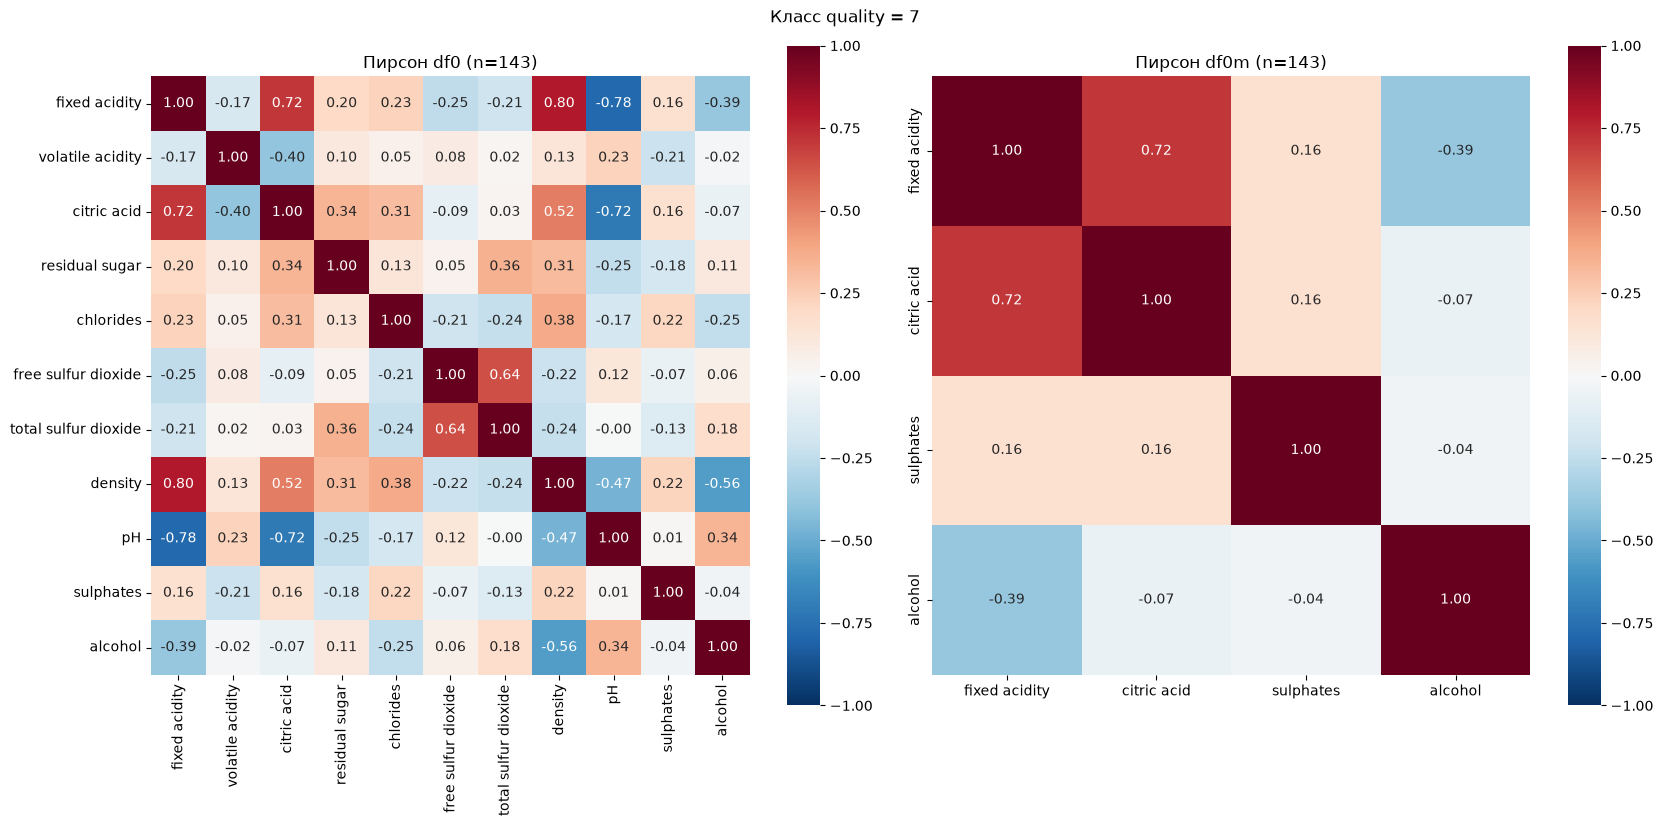

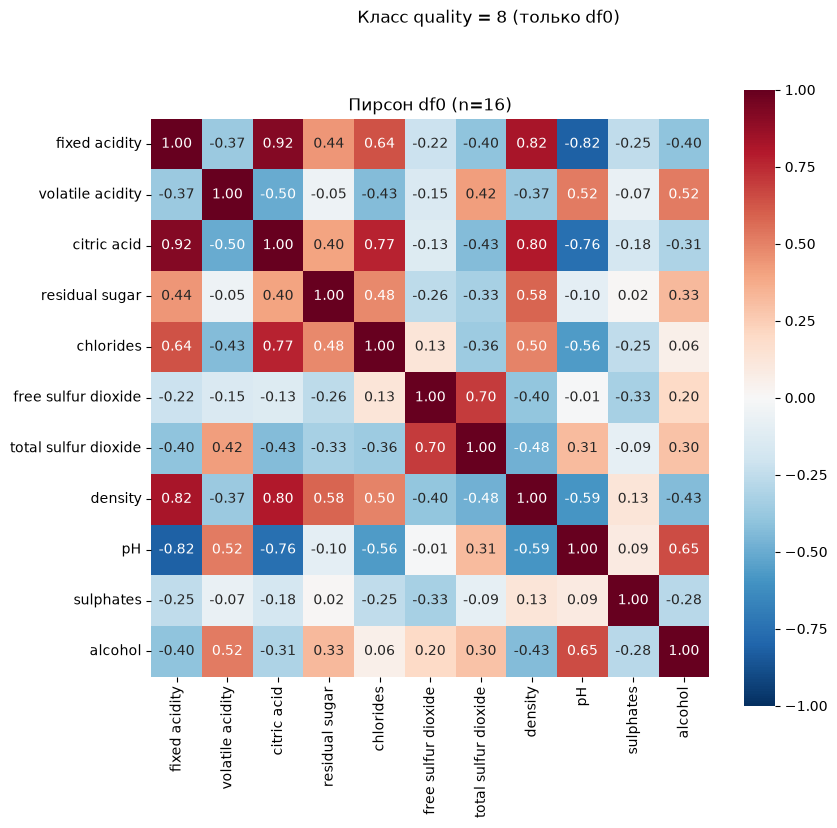

In [10]:
KW = dict(
    annot=True, fmt='.2f', cmap='RdBu_r',
    vmin=-1, vmax=1, center=0, square=True
)

classes_df0 = set(df0['quality'].unique())
classes_df0m = set(df0m['quality'].unique())
classes = sorted(classes_df0 | classes_df0m)

for cls in classes:
    in_df0 = cls in classes_df0
    in_df0m = cls in classes_df0m

    sub0 = df0[df0['quality'] == cls] if in_df0 else None
    sub0m = df0m[df0m['quality'] == cls] if in_df0m else None

    if in_df0 and in_df0m:
        fig, axes = plt.subplots(1, 2, figsize=(17, 8))
        fig.suptitle(f'Класс quality = {cls}')

        sns.heatmap(
            sub0[FEATURES].corr(method='pearson'),
            ax=axes[0],
            **KW
        ).set_title(f'Пирсон df0 (n={len(sub0)})')

        sns.heatmap(
            sub0m[quant_features].corr(method='pearson'),
            ax=axes[1],
            **KW
        ).set_title(f'Пирсон df0m (n={len(sub0m)})')

        plt.tight_layout()
        plt.show()

    elif in_df0:
        fig, ax = plt.subplots(1, 1, figsize=(9, 8))
        fig.suptitle(f'Класс quality = {cls} (только df0)')

        sns.heatmap(
            sub0[FEATURES].corr(method='pearson'),
            ax=ax,
            **KW
        ).set_title(f'Пирсон df0 (n={len(sub0)})')

[2.6] Выполнить визуализацию датасета по всем парам выбранных переменных, показав:
- на графиках разных пар признаков объекты классов разными по форме/цвету точками;
- в графиках с одной и той же парой переменных – диаграммы плотности распределения
каждого класса по оси признака

In [11]:
def plot_pair_matrix(
    df,
    features,
    class_col='quality',
    classes=None,
    show_regression=True,
    show_confidence=True,
    show_prediction=True
):

    if classes is None:
        classes = sorted(df[class_col].unique())

    colors = ["#6453C5", "#58B85D", "#E87950"]

    n = len(features)

    fig, axes = plt.subplots(
        n, n,
        figsize=(16, 16)
    )

    for i, y_feature in enumerate(features):
        for j, x_feature in enumerate(features):
            ax = axes[i, j]

            if i == j:
                for k, cls in enumerate(classes):
                    data = df.loc[
                        df[class_col] == cls,
                        x_feature
                    ].dropna()

                    sns.kdeplot(
                        data=data,
                        ax=ax,
                        color=colors[k],
                        linewidth=2,
                        fill=True,
                        alpha=0.25,
                        label=f'Класс {cls}'
                    )

                ax.set_xlabel('')
                ax.set_ylabel('')

                ax.set_title(
                    x_feature,
                    fontsize=12,
                    fontweight='bold'
                )

                ax.grid(True, alpha=0.25)

            else:
                # ADAPTIVE по всей ячейке: суммарное число точек всех классов
                n_cell = len(df[[x_feature, y_feature]].dropna())
                point_alpha = min(0.9, max(0.35, 200 / max(1, n_cell)))

                for k, cls in enumerate(classes):
                    data = df[
                        df[class_col] == cls
                    ][[x_feature, y_feature]].dropna()

                    x = data[x_feature].values
                    y = data[y_feature].values
                    n_cls = len(data)

                    if n_cls == 0:
                        continue

                    # # ADAPTIVE — прозрачность от числа точек этого класса
                    # point_alpha = min(0.9, max(0.4, 200 / max(1, n_cls)))

                    ax.scatter(
                        x,
                        y,
                        color=colors[k],
                        marker='o',
                        s=25,
                        alpha=point_alpha
                    )

                    if n_cls < 3:
                        continue

                    slope, intercept, r_value, p_value, std_err = \
                        stats.linregress(x, y)

                    x_pred = np.linspace(
                        x.min(),
                        x.max(),
                        200
                    )

                    y_pred = intercept + slope * x_pred
                    n_points = len(x)
                    x_mean = np.mean(x)

                    residuals = (
                        y - (intercept + slope * x)
                    )

                    s_err = np.sqrt(
                        np.sum(residuals ** 2)
                        / (n_points - 2)
                    )

                    t_value = stats.t.ppf(
                        0.975,
                        n_points - 2
                    )

                    x_variance = np.sum(
                        (x - x_mean) ** 2
                    )

                    if x_variance == 0:
                        continue

                    confidence = (
                        t_value
                        * s_err
                        * np.sqrt(
                            1 / n_points
                            + (x_pred - x_mean) ** 2
                            / x_variance
                        )
                    )

                    prediction = (
                        t_value
                        * s_err
                        * np.sqrt(
                            1
                            + 1 / n_points
                            + (x_pred - x_mean) ** 2
                            / x_variance
                        )
                    )

                    if show_prediction:
                        ax.fill_between(
                            x_pred,
                            y_pred - prediction,
                            y_pred + prediction,
                            color=colors[k],
                            alpha=0.08
                        )

                    if show_confidence:
                        ax.fill_between(
                            x_pred,
                            y_pred - confidence,
                            y_pred + confidence,
                            color=colors[k],
                            alpha=0.20
                        )

                    if show_regression:
                        ax.plot(
                            x_pred,
                            y_pred,
                            color=colors[k],
                            linewidth=2
                        )

                ax.grid(True, alpha=0.25)

            if i == n - 1:
                ax.set_xlabel(
                    x_feature,
                    fontsize=11
                )
            else:
                ax.set_xlabel('')

            if i == 0:
                ax.set_title(
                    x_feature,
                    fontsize=11
                )

            if j == 0:
                ax.set_ylabel(
                    y_feature,
                    fontsize=11
                )
            else:
                ax.set_ylabel('')

            if j == n - 1:
                ax.yaxis.set_label_position('right')
                ax.set_ylabel(
                    y_feature,
                    fontsize=11
                )

    handles = [
        plt.Line2D(
            [0],
            [0],
            marker='o',
            color='w',
            markerfacecolor=colors[k],
            markersize=8,
            label=f'Класс {cls}'
        )
        for k, cls in enumerate(classes)
    ]

    fig.legend(
        handles=handles,
        loc='upper right',
        fontsize=10
    )

    fig.suptitle(
        'Визуализация выбранных признаков по классам',
        fontsize=16,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()
    return fig

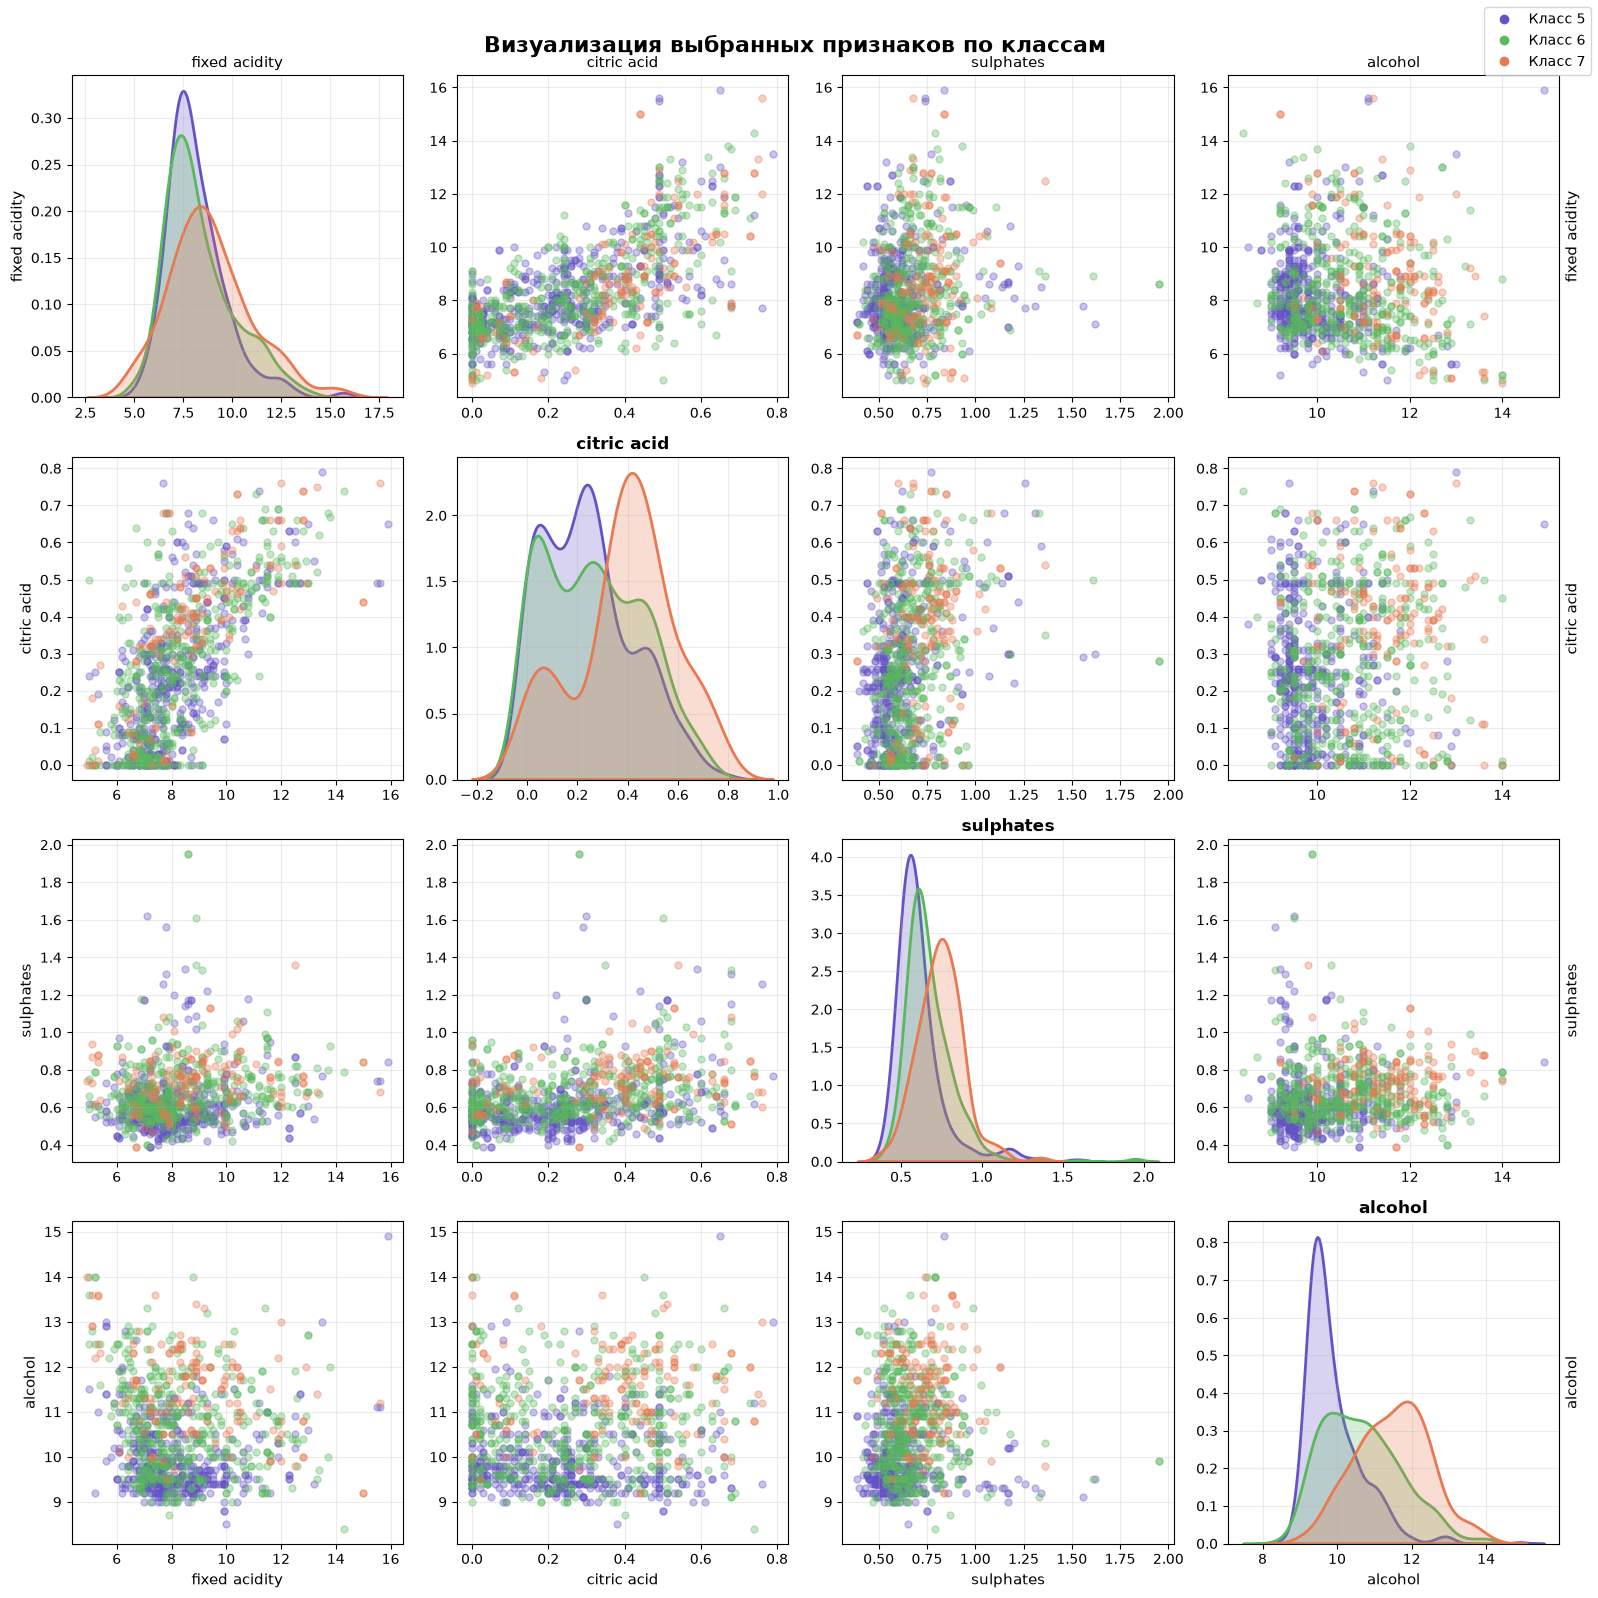

In [12]:
FEATURES = [
'fixed acidity',
    'citric acid',
    'sulphates',
    'alcohol',
]
fig = plot_pair_matrix(
    df0m,
    FEATURES,
    class_col='quality',
    classes=[5, 6, 7],
    show_confidence=False, 
    show_prediction=False,
    show_regression=False
)

[2.7] Выбрать один класс и пару признаков, для которых визуализировать с
использованием одиночного scatterplot с параметрами визуализации, регулируемыми
пользователем, линию линейной регрессии с соответствующими доверительными
(confidence bands) и прогнозными (predictive bands) полосами регрессий, предварительно
включаемыми/отключаемыми для отображения пользователем.

In [13]:
def plot_regression(
    df,
    x_feature,
    y_feature,
    class_value,
    class_col='quality'
):
    data = df[
        df[class_col] == class_value
    ][[x_feature, y_feature]].dropna()

    x = data[x_feature].values
    y = data[y_feature].values

    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

    x_pred = np.linspace(x.min(), x.max(), 200)
    y_pred = intercept + slope * x_pred

    n = len(x)
    x_mean = np.mean(x)

    residuals = y - (intercept + slope * x)

    s_err = np.sqrt(
        np.sum(residuals ** 2) / (n - 2)
    )

    t_value = stats.t.ppf(0.975, n - 2)

    x_variance = np.sum(
        (x - x_mean) ** 2
    )

    confidence = (
        t_value
        * s_err
        * np.sqrt(
            1 / n
            + (x_pred - x_mean) ** 2 / x_variance
        )
    )

    prediction = (
        t_value
        * s_err
        * np.sqrt(
            1
            + 1 / n
            + (x_pred - x_mean) ** 2 / x_variance
        )
    )

    # ADAPTIVE
    point_alpha = min(0.9, max(0.25, 200 / max(1, n)))

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.scatter(
        x,
        y,
        color='#6453C5',
        s=40,
        alpha=point_alpha,
        label=f'Класс {class_value}'
    )

    ax.plot(
        x_pred,
        y_pred,
        color="#6453C5",
        linewidth=2,
        label='Линия регрессии'
    )

    ax.fill_between(
        x_pred,
        y_pred - confidence,
        y_pred + confidence,
        color="#00FF2A",
        alpha=0.2,
        label='Confidence band'
    )

    ax.fill_between(
        x_pred,
        y_pred - prediction,
        y_pred + prediction,
        color="#FF0000",
        alpha=0.15,
        label='Prediction band'
    )

    ax.set_xlabel(x_feature)
    ax.set_ylabel(y_feature)

    ax.set_title(
        f'Класс {class_value}: {x_feature} и {y_feature}'
    )

    ax.grid(True, alpha=0.25)
    ax.legend()

    plt.show()

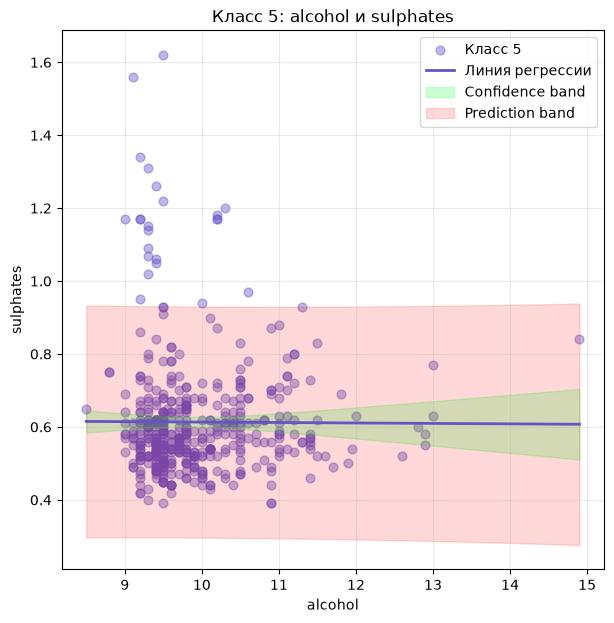

In [14]:
CLASS = 5

FEATURES_27 = [
    'alcohol',
    'sulphates'
]

df27 = df0m[
    df0m['quality'] == CLASS
][FEATURES_27 + ['quality']].copy()

plot_regression(
    df27,
    x_feature='alcohol',
    y_feature='sulphates',
    class_col='quality',
    class_value=CLASS
)

[2.8] Отдельно повторно выполнить пункт [2.6], отобразив на каждом из графиков для
каждого из классов линию линейной регрессии с соответствующими прогнозными
(predictive bands) полосами регрессий, которые возможно опционально
включить/отключить перед отображением.

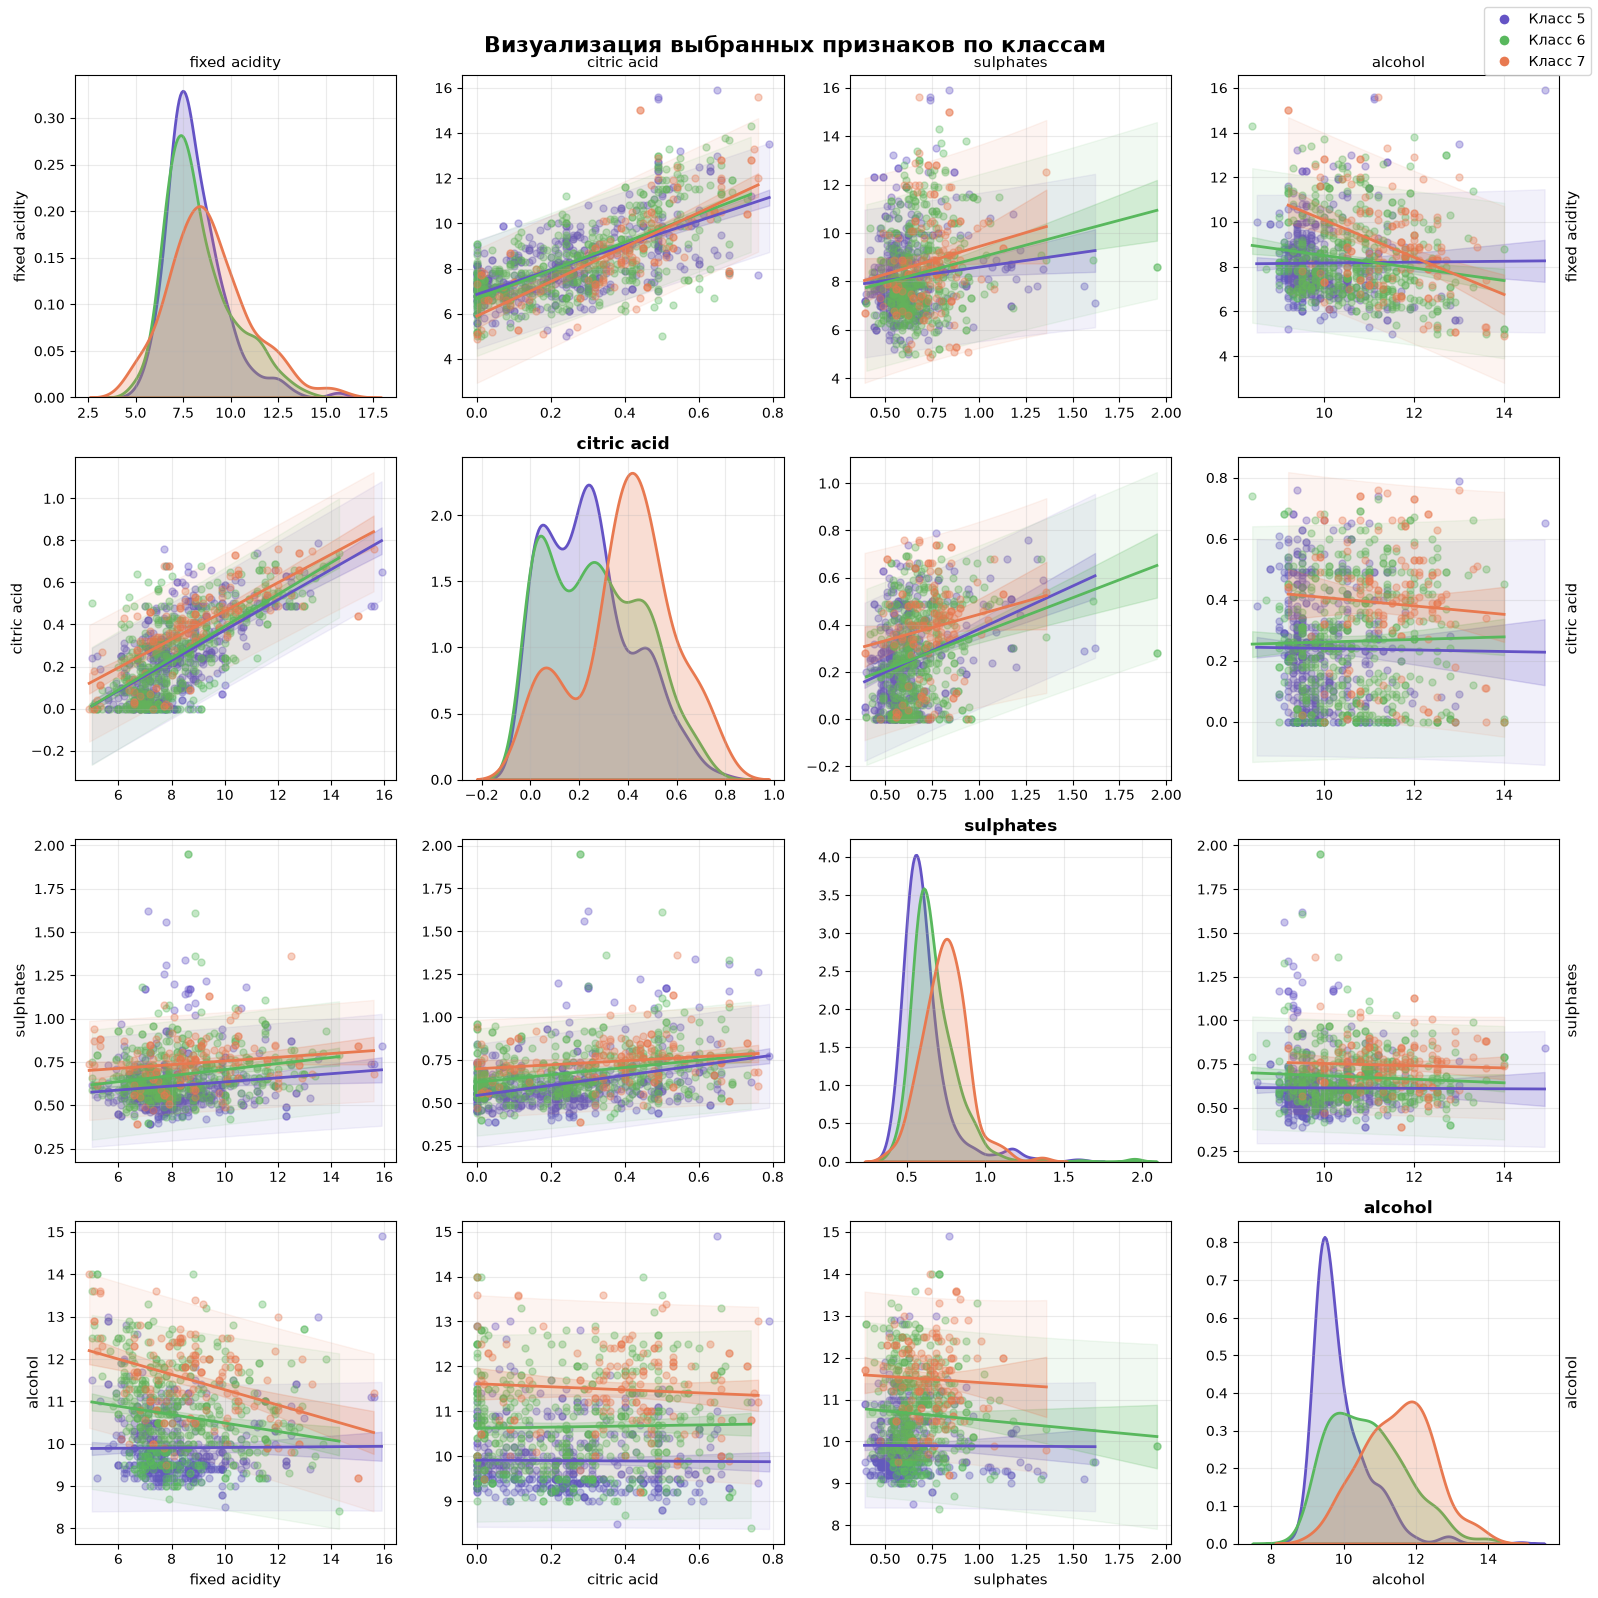

In [15]:
FEATURES = [
'fixed acidity',
    'citric acid',
    'sulphates',
    'alcohol',
]
fig = plot_pair_matrix(
    df0m,
    FEATURES,
    class_col='quality',
    classes=[5, 6, 7],
    show_confidence=True, 
    show_prediction=True,
    show_regression=True
)

[2.9] Вывести формулы каждой оцененной линейной регрессии вместе со значениями
критерия R^2 и критериев Вальда, LR и score (для каждого вывести F-критерий, его
степени свободы и соответствующий p-критерий).

In [16]:
def linear_regression_report(df, features, class_col='quality', classes=None):
    if classes is None:
        classes = sorted(df[class_col].dropna().unique())

    rows = []
    for cls in classes:
        sub = df[df[class_col] == cls]
        for x_name in features:
            for y_name in features:
                if x_name == y_name:
                    continue

                data = sub[[x_name, y_name]].dropna()
                n = len(data)
                if n < 3:
                    continue

                x = data[x_name].to_numpy(dtype=float)
                y = data[y_name].to_numpy(dtype=float)

                x_bar = x.mean()
                y_bar = y.mean()
                sxx = np.sum((x - x_bar) ** 2)
                syy = np.sum((y - y_bar) ** 2)
                sxy = np.sum((x - x_bar) * (y - y_bar))

                b1 = sxy / sxx
                b0 = y_bar - b1 * x_bar

                rss_full = syy - b1 * sxy
                rss_null = syy
                r2 = 1 - rss_full / syy

                df1 = 1
                df2 = n - 2

                wald_f = b1 ** 2 / ((rss_full / df2) / sxx)

                lr_chi2 = n * np.log(rss_null / rss_full)
                lr_f = df2 * (np.exp(lr_chi2 / n) - 1)

                score_chi2 = n * r2
                score_f = df2 * score_chi2 / (n - score_chi2)

                sign = '+' if b1 >= 0 else '-'
                formula = f'{y_name} = {b0:.4g} {sign} {abs(b1):.4g}\u00b7{x_name}'

                rows.append({
                    'Класс': cls,
                    'Формула': formula,
                    'R2': r2,
                    'Вальд F': wald_f,
                    'Вальд p': stats.f.sf(wald_f, df1, df2),
                    'LR F': lr_f,
                    'LR p': stats.f.sf(lr_f, df1, df2),
                    'score F': score_f,
                    'score p': stats.f.sf(score_f, df1, df2),
                    'df1': df1,
                    'df2': df2,
                })

    return pd.DataFrame(rows)


FEATURES_29 = ['fixed acidity', 'citric acid', 'sulphates', 'alcohol']

regression_report = linear_regression_report(
    df0m,
    FEATURES_29,
    class_col='quality',
    classes=[5, 6, 7]
)

display_report = regression_report.copy()
for col in ['R2', 'Вальд F', 'Вальд p', 'LR F', 'LR p', 'score F', 'score p']:
    display_report[col] = display_report[col].map(lambda v: f'{v:.4g}')

display_report

,Класс,Формула,R2,Вальд F,Вальд p,LR F,LR p,score F,score p,df1,df2
0,5,citric acid = -0.3492 + 0.07221·fixed acidity,0.3918,309.9,6.634e-54,309.9,6.634e-54,309.9,6.634e-54,1,481
1,5,sulphates = 0.517 + 0.0118·fixed acidity,0.01305,6.358,0.01201,6.358,0.01201,6.358,0.01201,1,481
2,5,alcohol = 9.864 + 0.004641·fixed acidity,9.227e-05,0.04438,0.8332,0.04438,0.8332,0.04438,0.8332,1,481
3,5,fixed acidity = 6.858 + 5.426·citric acid,0.3918,309.9,6.634e-54,309.9,6.634e-54,309.9,6.634e-54,1,481
4,5,sulphates = 0.543 + 0.2931·citric acid,0.107,57.65,1.645e-13,57.65,1.645e-13,57.65,1.645e-13,1,481
5,5,alcohol = 9.913 - 0.04389·citric acid,0.0001098,0.05283,0.8183,0.05283,0.8183,0.05283,0.8183,1,481
6,5,fixed acidity = 7.483 + 1.105·sulphates,0.01305,6.358,0.01201,6.358,0.01201,6.358,0.01201,1,481
7,5,citric acid = 0.01613 + 0.3652·sulphates,0.107,57.65,1.645e-13,57.65,1.645e-13,57.65,1.645e-13,1,481
8,5,alcohol = 9.919 - 0.02652·sulphates,3.217e-05,0.01547,0.9011,0.01547,0.9011,0.01547,0.9011,1,481
9,5,fixed acidity = 7.964 + 0.01988·alcohol,9.227e-05,0.04438,0.8332,0.04438,0.8332,0.04438,0.8332,1,481


[2.10] Визуализировать один количественный признак, выбираемый пользователем, для
каждого из классов в виде raincloud plot with jittering, рядом с которым в виде boxplot
отображены медианы, межквартильные размахи (IQR) и доверительные интервалы.

In [17]:
import ptitprince as pt

def raincloud_plot_class(df0, feature, target, classes=None,
                         colors=None, figsize=(8, 9),
                         jitter_y=0.2, jitter_x=None, seed=42,
                         box_h=0.18, box_gap=0.06):
    rng = np.random.default_rng(seed)

    if classes is None:
        classes = sorted(df0[target].dropna().unique())

    df_long = df0[[feature, target]].dropna().copy()
    df_long = df_long[df_long[target].isin(classes)]
    df_long['class_str'] = df_long[target].astype(str)
    df_long = df_long.rename(columns={feature: 'value'})

    order = [str(c) for c in classes]

    if jitter_x is None:
        rng_x = df_long['value'].max() - df_long['value'].min()
        jitter_x = 0.015 * rng_x if rng_x > 0 else 0.0

    if colors is None:
        base_palette = ["#EE8588", "#F9D173", "#95E9F2", "#E2B7F4",
                        "#B5EAD7", "#FFB7B2", "#C7CEEA", "#FFDAC1"]
        colors = [base_palette[i % len(base_palette)] for i in range(len(order))]

    fig, ax = plt.subplots(figsize=figsize)

    pt.half_violinplot(
        x='value', y='class_str', data=df_long,
        order=order,
        palette=colors,
        inner=None,
        width=0.6,
        ax=ax,
    )

    SHIFT = jitter_y + box_gap + box_h / 2.0
    POSITIONS = [i + SHIFT for i in range(len(order))]

    boxplot_data = [
        df_long[df_long['class_str'] == cls]['value'].values
        for cls in order
    ]
    ax.boxplot(
        boxplot_data,
        vert=False,
        positions=POSITIONS,
        widths=box_h,
        manage_ticks=False,
        whis=1.5,
        showfliers=False,
        showcaps=True, capwidths=0.1,
        medianprops ={'linewidth': 1.5, 'color': "#000000"},
        boxprops    ={'linewidth': 1.5, 'color': "#000000"},
        whiskerprops={'linewidth': 1.5, 'color': "#000000"},
        capprops    ={'linewidth': 1.5, 'color': "#000000"},
    )

    for i, cls in enumerate(order):
        data = df_long[df_long['class_str'] == cls]
        if data.empty:
            continue
        n = len(data)
        x = data['value'].values + rng.uniform(-jitter_x, jitter_x, size=n)
        y = i + np.random.uniform(low=0.0, high=jitter_y, size=n)

        point_alpha = min(0.9, max(0.25, 200 / max(1, n)))

        ax.scatter(x, y, color=colors[i],
                   alpha=point_alpha, s=30,
                   edgecolor=colors[i], linewidths=0.5)

    ax.set_xlabel('Значение', fontsize=15)
    ax.set_ylabel(target, fontsize=15)
    ax.set_title(f'Raincloud plot: "{feature}" по классам "{target}"', fontsize=18)
    ax.tick_params(labelsize=13)

    plt.tight_layout()
    plt.show()

/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_13419/2912160347.py:46: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


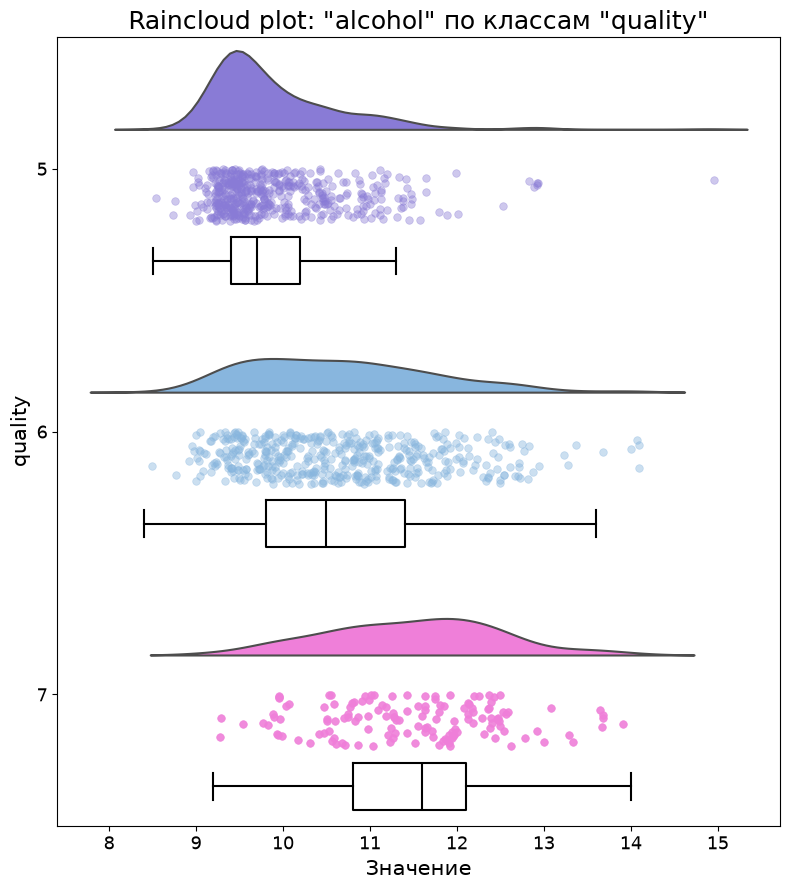

In [18]:
raincloud_plot_class(
    df0m,
    feature='alcohol',
    target='quality',
    classes=[5, 6, 7],
    colors=["#897BD6", "#88B6DE", "#EF7FD9"]
)

[2.11] Выполнить дисперсионный анализ (ANOVA) по одному из признаков, выбираемому
пользователем: рассчитать общий F-критерий, его степени свободы df1 и df2 и
соответствующий ему p-критерий для всех классов одновременно, а также для каждой
пары классов.

In [19]:
def anova_feature(df0, feature, target, classes=None):
    if classes is None:
        classes = sorted(df0[target].dropna().unique())
    classes = list(classes)

    df = df0[[feature, target]].dropna()
    df = df[df[target].isin(classes)]

    groups = [df.loc[df[target] == c, feature].values for c in classes]

    F_all, p_all = stats.f_oneway(*groups)

    k = len(classes)
    N = sum(len(g) for g in groups)

    df1_all = k - 1
    df2_all = N - k

    rows = []
    for c1, c2 in combinations(classes, 2):
        g1 = df.loc[df[target] == c1, feature].values
        g2 = df.loc[df[target] == c2, feature].values
        if len(g1) < 2 or len(g2) < 2:
            continue
        F_pair, p_pair = stats.f_oneway(g1, g2)
        rows.append({
            'class_1': c1,
            'class_2': c2,
            'F':   F_pair,
            'df1': 1,
            'df2': len(g1) + len(g2) - 2,
            'p':   p_pair,
        })
    pairwise = pd.DataFrame(rows)

    print("=" * 72)
    print(f"ANOVA:  признак = '{feature}',  классы ({target}) = {classes}")
    print("=" * 72)

    print("\nОБЩИЙ F-критерий (все классы одновременно):")
    print(f"  F    = {F_all:.4f}")
    print(f"  df1  = {df1_all}")
    print(f"  df2  = {df2_all}")
    print(f"  p    = {p_all:.6g}")

    print("\nПопарные сравнения:")
    if pairwise.empty:
        print("  (недостаточно данных)")
    else:
        with pd.option_context('display.float_format', '{:.6g}'.format):
            print(pairwise.to_string(index=False))

    return {
        'overall':  {'F': F_all, 'df1': df1_all, 'df2': df2_all, 'p': p_all},
        'pairwise': pairwise,
    }

In [20]:
res = anova_feature(
    df0m,
    feature='alcohol',
    target='quality',
    classes=[5, 6, 7],
)

ANOVA:  признак = 'alcohol',  классы (quality) = [5, 6, 7]

ОБЩИЙ F-критерий (все классы одновременно):
  F    = 186.1978
  df1  = 2
  df2  = 1085
  p    = 3.01893e-70

Попарные сравнения:
 class_1  class_2       F  df1  df2           p
       5        6 160.774    1  943 3.93047e-34
       5        7 419.931    1  624 9.39364e-72
       6        7 69.4508    1  603 5.30387e-16


[2.12**] Используя функцию multivariate_normal из numpy, отдельным блоком ipynb
cгенерировать и визуализировать датасет dfG случайной формы распределения (за счет
матрицы ковариаций гауссиана, без вывода цифр), в котором есть два количественных
(недискретных) признака и 1 класс случайным размером 10-100 объектов.
Используя датасет dfG, повторно визуализировать dfG, добавив на визуализацию
значение корреляции Пирсона, линию регрессии с соответствующими доверительными
(confidence bands) и прогнозными (predictive bands) полосами регрессий.

In [21]:
rng = np.random.default_rng()

n = int(rng.integers(10, 101))

A = rng.uniform(-1, 1, size=(2, 2))
cov = A @ A.T
mean = rng.uniform(-5, 5, size=2)

X = rng.multivariate_normal(mean=mean, cov=cov, size=n)

dfG = pd.DataFrame({
    'feature_1': X[:, 0],
    'feature_2': X[:, 1],
    'class': rng.choice(['A', 'B'], size=n)
})

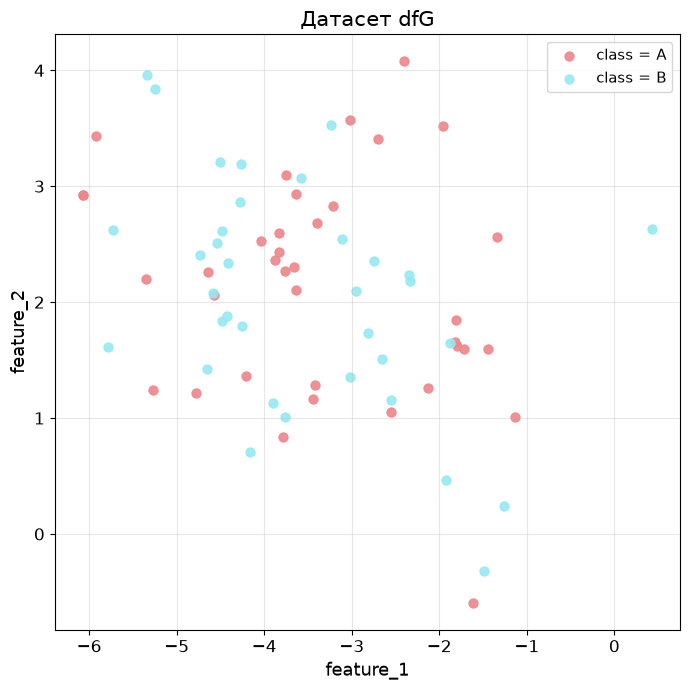

In [22]:
fig, ax = plt.subplots(figsize=(7, 7))

palette = ['#EE8588', '#95E9F2', '#F9D173', '#E2B7F4']
for cls, color in zip(dfG['class'].unique(), palette):
    sub = dfG[dfG['class'] == cls]
    # ADAPTIVE
    total_points = len(sub)
    point_alpha = min(0.9, max(0.25, 200 / max(1, total_points)))
    ax.scatter(sub['feature_1'], sub['feature_2'],
               color=color, alpha=point_alpha, s=45,
               edgecolor=color, linewidths=0.7, label=f'class = {cls}')

ax.set_xlabel('feature_1', fontsize=13)
ax.set_ylabel('feature_2', fontsize=13)
ax.set_title('Датасет dfG', fontsize=15)
ax.legend(loc='best', fontsize=11, frameon=True)
ax.tick_params(labelsize=12)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


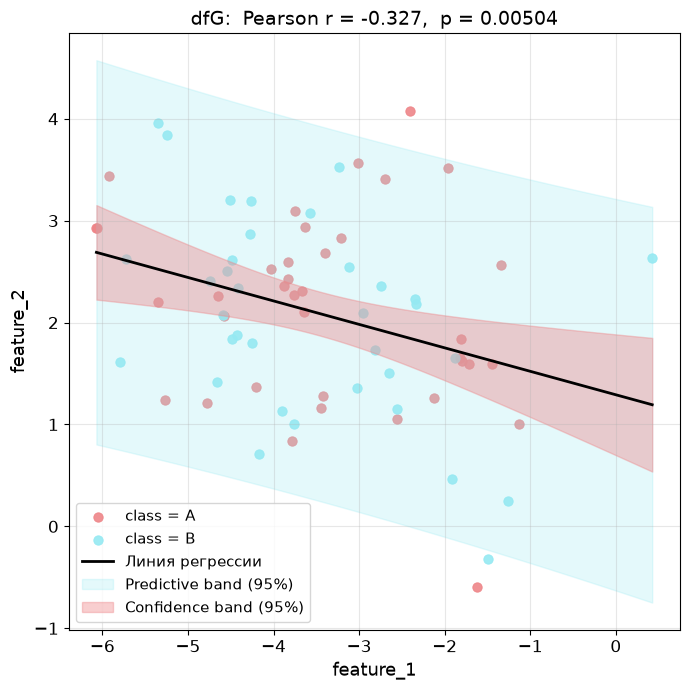

In [23]:
x = dfG['feature_1'].values
y = dfG['feature_2'].values

r, p_pearson = stats.pearsonr(x, y)

slope, intercept, _, _, _ = stats.linregress(x, y)

x_sorted = np.linspace(x.min(), x.max(), 200)
y_hat = intercept + slope * x_sorted

n = len(x)
residuals = y - (intercept + slope * x)
s = np.sqrt(np.sum(residuals ** 2) / (n - 2))
x_mean = x.mean()
Sxx = np.sum((x - x_mean) ** 2)

t_crit = stats.t.ppf(0.975, df=n - 2)

se_mean = s * np.sqrt(1 / n + (x_sorted - x_mean) ** 2 / Sxx)
se_pred = s * np.sqrt(1 + 1 / n + (x_sorted - x_mean) ** 2 / Sxx)

conf_lo = y_hat - t_crit * se_mean
conf_hi = y_hat + t_crit * se_mean
pred_lo = y_hat - t_crit * se_pred
pred_hi = y_hat + t_crit * se_pred

fig, ax = plt.subplots(figsize=(7, 7))

palette = ['#EE8588', '#95E9F2', '#F9D173', '#E2B7F4']
for cls, color in zip(dfG['class'].unique(), palette):
    sub = dfG[dfG['class'] == cls]
    # ADAPTIVE
    total_points = len(sub)
    point_alpha = min(0.9, max(0.25, 200 / max(1, total_points)))
    ax.scatter(sub['feature_1'], sub['feature_2'],
               color=color, alpha=point_alpha, s=45,
               edgecolor=color, linewidths=0.7,
               label=f'class = {cls}')

ax.plot(x_sorted, y_hat, color='black', linewidth=2, label='Линия регрессии')

ax.fill_between(x_sorted, pred_lo, pred_hi,
                color='#95E9F2', alpha=0.25,
                label='Predictive band (95%)')
ax.fill_between(x_sorted, conf_lo, conf_hi,
                color='#EE8588', alpha=0.40,
                label='Confidence band (95%)')

ax.set_xlabel('feature_1', fontsize=13)
ax.set_ylabel('feature_2', fontsize=13)
ax.set_title(f'dfG:  Pearson r = {r:.3f},  p = {p_pearson:.3g}',
             fontsize=14)
ax.legend(loc='best', fontsize=11, frameon=True)
ax.tick_params(labelsize=12)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
